[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/istvan-knab/latent_crew/blob/main/docs/milestones/milestone_1.ipynb)

# Milestone 1 – Dataset documentation

This notebook documents every dataset available to the Latent Crew project:
what the data is, where it comes from, what we use it for, which labels it has,
and why we chose it.

Datasets:

1. **NYU Depth V2** (labeled subset)
2. **SUN RGB-D** (V1)

**How to run.** The notebook reads the outputs of the data pipeline, so run these first
from the repository root (see `data/README.md`):

```
python data/scripts/collect_data.py
python data/scripts/data_evaluation.py
```

The statistics come from `data/reports/data_evaluation.json`, which is computed over the
same `index.jsonl` files that training uses. Extra packages needed only for the notebook:
`matplotlib` and `ipykernel`.

## 0. Setup

In [ ]:
import os
import subprocess
import sys

# On Colab the repository is not there yet: clone it, install the packages and (optionally)
# run the data pipeline. Locally this cell does nothing.
RUN_PIPELINE = False  # True: download (about 10 GB) and prepare the data, then evaluate it

if "google.colab" in sys.modules:
    if not os.path.exists("latent_crew"):
        subprocess.run(["git", "clone", "https://github.com/istvan-knab/latent_crew.git"], check=True)
    os.chdir("latent_crew")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "data/requirements.txt"], check=True)
    if RUN_PIPELINE:
        subprocess.run([sys.executable, "data/scripts/collect_data.py"], check=True)
        subprocess.run([sys.executable, "data/scripts/data_evaluation.py"], check=True)


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from PIL import Image

# Works whether the kernel starts in the repo root or in data/
DATA_ROOT = Path.cwd() if (Path.cwd() / "config.toml").exists() else Path.cwd() / "data"
REPORT_PATH = DATA_ROOT / "reports" / "data_evaluation.json"
DATASETS = {"nyu_depth_v2": "NYU Depth V2", "sunrgbd": "SUN RGB-D"}

if not REPORT_PATH.exists():
    raise FileNotFoundError(
        f"{REPORT_PATH} not found. Run python data/scripts/collect_data.py "
        "and python data/scripts/data_evaluation.py from the repository root first."
    )
report = json.loads(REPORT_PATH.read_text(encoding="utf-8"))
stats = report["datasets"]
if report["sample_limit"] is not None:
    print(f"Warning: the report was computed on a sample (sample_limit={report['sample_limit']}).")


def load_index(dataset: str) -> list[dict]:
    path = DATA_ROOT / "processed" / dataset / "index.jsonl"
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


index = {name: load_index(name) for name in DATASETS}
print(f"Report created: {report['created']}")
for name, title in DATASETS.items():
    print(f"{title}: {len(index[name])} samples in index.jsonl")

Report created: 2026-10-08T16:36:19
NYU Depth V2: 1449 samples in index.jsonl
SUN RGB-D: 10335 samples in index.jsonl


Helper functions shared by the dataset sections (tables and plots).

In [2]:
MODALITIES = {
    "rgb": "RGB image",
    "depth": "Depth, filled",
    "depth_raw": "Depth, raw sensor",
    "semantic": "Semantic label map",
    "instance": "Instance map",
}
DEPTH_CMAP = plt.get_cmap("viridis").with_extremes(bad="black")


def md_table(header: list[str], rows: list[list]) -> None:
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def sorted_classes(name: str) -> list[dict]:
    return sorted(stats[name]["labels"]["per_class"], key=lambda c: -c["pixels"])


def show_overview(name: str) -> None:
    s = stats[name]["structure"]
    rows = []
    for key, desc in MODALITIES.items():
        f = s["files"][key]
        res = ", ".join(f"{r} ({n})" for r, n in sorted(f["resolution"].items(), key=lambda kv: -kv[1]))
        rows.append([desc, f"`{key}`", ", ".join(f["format"]), ", ".join(f["dtype"]), res])
    md_table(["Modality", "Index field", "Format", "dtype", "Resolution W×H (samples)"], rows)
    n, du = s["samples"], s["disk_usage"]
    md_table(
        ["Samples", "Train", "Test", "Train share", "Download size", "Processed size", "Processed files"],
        [[n["total"], n["train"], n["test"], f"{n['train_ratio']:.1%}", du["downloads"], du["processed"], du["processed_files"]]],
    )


def show_depth_summary(name: str) -> None:
    d = stats[name]["depth"]
    rows = []
    for key in ("depth", "depth_raw"):
        v, p = d[key]["valid_pixels"], d[key]["valid_pixels"]["percentiles"]
        rows.append([
            MODALITIES[key],
            f"{v['min'] / 1000:.2f}", f"{p['1'] / 1000:.2f}", f"{v['median'] / 1000:.2f}",
            f"{p['99'] / 1000:.2f}", f"{v['max'] / 1000:.2f}",
            f"{d[key]['pixel_ratios']['invalid']:.1%}", f"{d[key]['valid_ratio_per_sample']['min']:.1%}",
        ])
    md_table(["Depth map", "Min (m)", "P1 (m)", "Median (m)", "P99 (m)", "Max (m)",
              "Missing pixels", "Worst sample: valid pixels"], rows)


def show_samples(name: str, n: int = 4, seed: int = 0) -> None:
    rows = index[name]
    picks = [rows[i] for i in sorted(np.random.default_rng(seed).choice(len(rows), n, replace=False))]
    num_classes = len(stats[name]["labels"]["class_names"])
    palette = np.random.default_rng(0).random((num_classes, 3))
    palette[0] = 0  # unlabeled = black
    root = DATA_ROOT / "processed" / name
    cols = ["rgb", "depth", "depth_raw", "semantic"]
    fig, axes = plt.subplots(n, len(cols), figsize=(14, 2.7 * n))
    for r, row in enumerate(picks):
        for c, key in enumerate(cols):
            a = np.asarray(Image.open(root / row[key]))
            ax = axes[r, c]
            if key.startswith("depth"):
                im = ax.imshow(np.ma.masked_equal(a, 0) / 1000, cmap=DEPTH_CMAP, vmin=0, vmax=8)
            elif key == "semantic":
                ax.imshow(palette[a], interpolation="nearest")
            else:
                ax.imshow(a)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(MODALITIES[key])
        axes[r, 0].set_ylabel(f"{row['id']}\n{row['scene']}\n{row['sensor']}", fontsize=8)
    fig.colorbar(im, ax=axes[:, 1:3], shrink=0.6, label="depth (m), black = no measurement")
    plt.show()


def plot_scenes(name: str, top: int = 20) -> None:
    counts = stats[name]["alignment"]["scenes"]["counts"]
    items = sorted(counts.items(), key=lambda kv: -(kv[1]["train"] + kv[1]["test"]))[:top][::-1]
    labels = [k for k, _ in items]
    train = np.array([v["train"] for _, v in items])
    test = np.array([v["test"] for _, v in items])
    fig, ax = plt.subplots(figsize=(9, 0.28 * len(items) + 1))
    ax.barh(labels, train, label="train")
    ax.barh(labels, test, left=train, label="test")
    ax.set_xlabel("samples")
    ax.set_title(f"{DATASETS[name]}: {len(items)} most common of {len(counts)} scene types")
    ax.legend()
    plt.show()


def plot_class_distribution(name: str, top: int | None = None) -> None:
    shown = sorted_classes(name)[:top][::-1]
    labels = [c["name"] for c in shown]
    fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(13, 0.24 * len(shown) + 1.5))
    ax1.barh(labels, [100 * c["labelled_ratio"] for c in shown])
    ax1.set_xscale("log")
    ax1.set_xlabel("share of labelled pixels (%, log scale)")
    ax2.barh(labels, [c["images"] for c in shown], color="tab:orange")
    ax2.set_xlabel(f"images containing the class (of {stats[name]['labels']['checked_samples']})")
    total = len(stats[name]["labels"]["per_class"])
    shown_txt = f"top {len(shown)} of {total}" if len(shown) < total else f"all {total}"
    fig.suptitle(f"{DATASETS[name]}: class distribution, {shown_txt} classes")
    fig.tight_layout()
    plt.show()


def class_table(name: str, top: int | None = None) -> None:
    rows = []
    for rank, c in enumerate(sorted_classes(name)[:top], 1):
        per_img = c["instances"] / c["images"] if c["images"] else 0
        rows.append([rank, c["id"], c["name"], f"{c['labelled_ratio']:.2%}", c["images"], c["instances"], f"{per_img:.1f}"])
    md_table(["Rank", "Id", "Class", "Pixel share", "Images", "Instances", "Instances / image"], rows)


def plot_class_coverage(names: list[str]) -> None:
    fig, ax = plt.subplots(figsize=(8, 4))
    for name in names:
        share = np.cumsum([c["labelled_ratio"] for c in sorted_classes(name)])
        ax.plot(np.arange(1, len(share) + 1), 100 * share, marker=".", label=DATASETS[name])
    ax.axhline(90, color="grey", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("number of most frequent classes (log scale)")
    ax.set_ylabel("cumulative share of labelled pixels (%)")
    ax.set_title("How many classes cover the labelled pixels")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()


def show_quality(name: str) -> None:
    d = stats[name]
    s = d["structure"]
    rows = [
        ["structure", "missing files", sum(s["missing_files"].values()) if s["missing_files"] else 0, ""],
        ["structure", "unreadable files", sum(s["unreadable_files"].values()) if s["unreadable_files"] else 0, ""],
        ["structure", "incomplete samples", s["incomplete_samples"], ""],
        ["structure", "duplicate ids / paths",
         s["index_issues"]["duplicate_ids"] + s["index_issues"]["duplicate_paths"], ""],
    ]
    for check in ("rgb", "depth", "labels", "alignment"):
        for flag, v in d[check]["flagged"].items():
            if flag.startswith("bad_box") and not isinstance(d["labels"]["boxes"], dict):
                continue  # dataset has no boxes
            rows.append([check, flag.replace("_", " "), v["count"], ", ".join(v["examples"][:3])])
    dup = d["alignment"]["duplicates"]
    rows.append(["alignment", "near-duplicate train/test pairs", dup["near_pairs_train_test"], ""])
    md_table(["Check", "Issue", "Samples", "Examples"], rows)
    ex = d["alignment"]["exclude_candidates"]
    by = ", ".join(f"{k}: {v}" for k, v in ex["by_check"].items())
    total = s["samples"]["total"]
    display(Markdown(f"**Exclusion candidates:** {ex['samples']} of {total} samples "
                     f"({ex['samples'] / total:.1%}); by check: {by}. "
                     "The full list is in `data/reports/problematic_samples.jsonl`."))

## 1. NYU Depth V2

### 1.1 What the data is

The labeled subset of **NYU Depth V2** (Silberman et al., *Indoor Segmentation and Support
Inference from RGBD Images*, ECCV 2012). It contains **1449 densely annotated RGB-D frames**
of indoor scenes (homes, offices, shops) recorded with a **Microsoft Kinect v1**. Every frame
has an RGB image, an aligned depth map and per-pixel semantic and instance labels.

Modalities after our preparation step (`data/processed/nyu_depth_v2/`):

- **RGB**: 640×480, 8-bit, JPEG.
- **Depth, filled**: depth in millimetres as 16-bit PNG. The holes of the sensor were filled by the
  dataset authors with a colorization-based in-painting, so every pixel has a value.
- **Depth, raw**: the original Kinect measurement, 0 means "no measurement".
- **Semantic labels**: one class id per pixel (0 = unlabeled, 1–894 = classes), 16-bit PNG.
- **Instance map**: object instance ids within the image, 8-bit PNG.
- Metadata in `index.jsonl`: split, scene type, sensor.

In [3]:
show_overview("nyu_depth_v2")
show_depth_summary("nyu_depth_v2")

| Modality | Index field | Format | dtype | Resolution W×H (samples) |
|---|---|---|---|---|
| RGB image | `rgb` | JPEG | uint8 | 640x480 (1449) |
| Depth, filled | `depth` | PNG | uint16 | 640x480 (1449) |
| Depth, raw sensor | `depth_raw` | PNG | uint16 | 640x480 (1449) |
| Semantic label map | `semantic` | PNG | uint16 | 640x480 (1449) |
| Instance map | `instance` | PNG | uint8 | 640x480 (1449) |

| Samples | Train | Test | Train share | Download size | Processed size | Processed files |
|---|---|---|---|---|---|---|
| 1449 | 795 | 654 | 54.9% | 2.8 GiB | 618.6 MiB | 7247 |

| Depth map | Min (m) | P1 (m) | Median (m) | P99 (m) | Max (m) | Missing pixels | Worst sample: valid pixels |
|---|---|---|---|---|---|---|---|
| Depth, filled | 0.71 | 0.83 | 2.51 | 7.55 | 9.99 | 0.0% | 100.0% |
| Depth, raw sensor | 0.71 | 0.86 | 2.46 | 7.24 | 10.00 | 31.4% | 14.9% |

Four random samples (fixed seed). Depth is shown in metres; black pixels in the raw depth are
the sensor holes that the filled version replaces. Label colours are arbitrary, black is unlabeled.

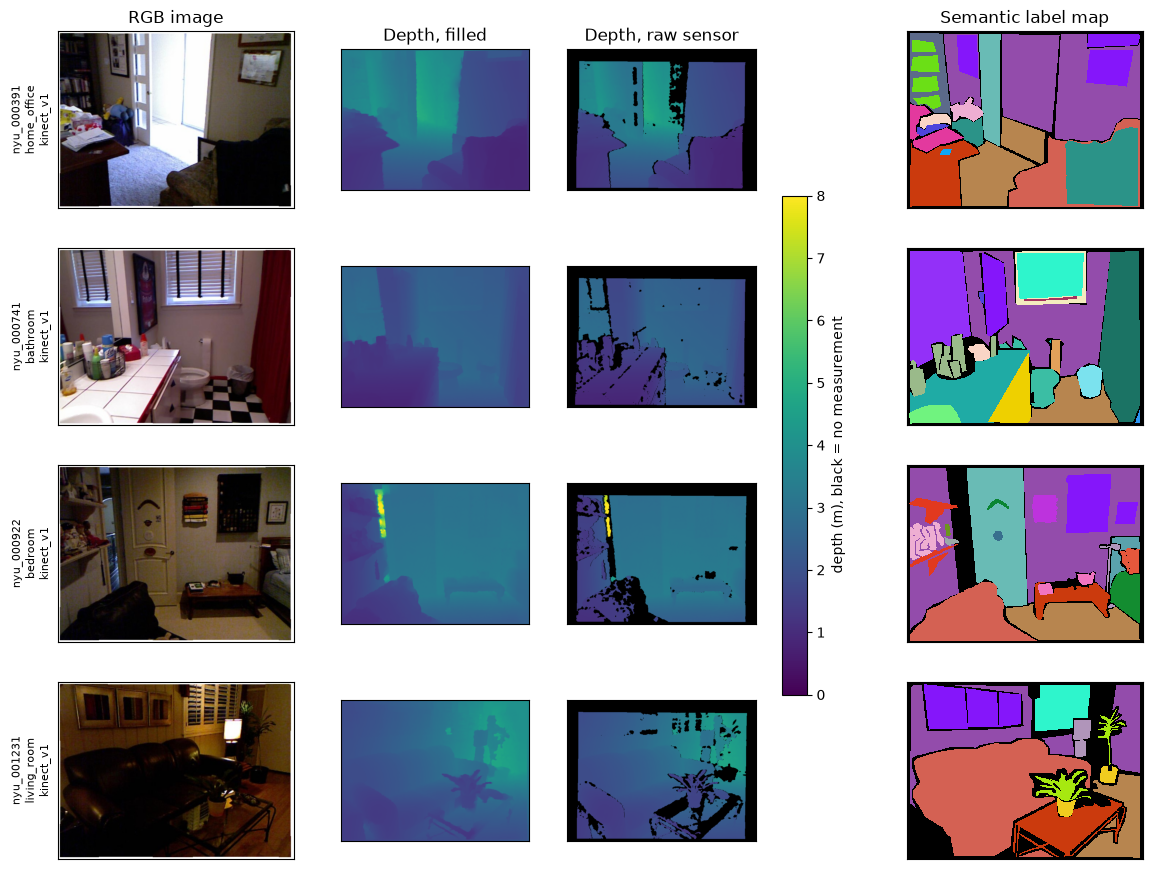

In [4]:
show_samples("nyu_depth_v2")

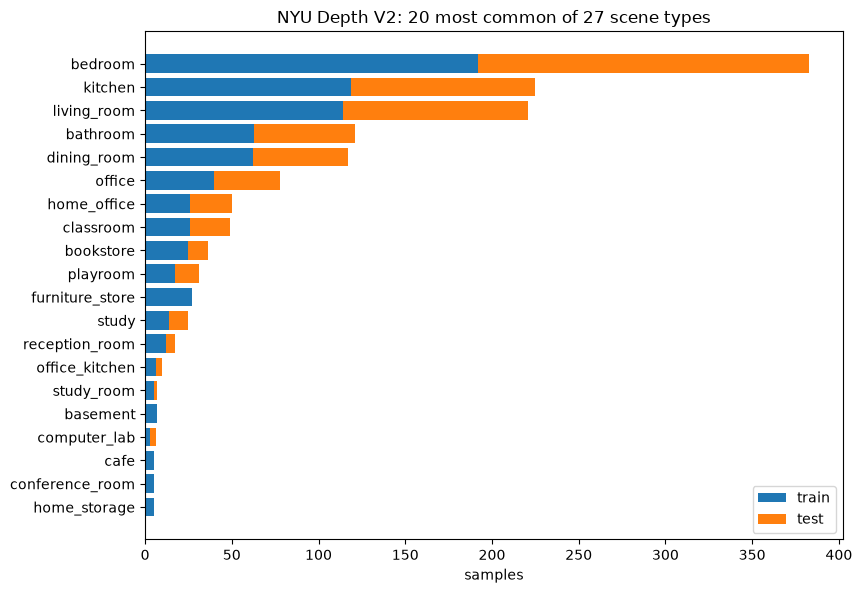

In [5]:
plot_scenes("nyu_depth_v2")

### 1.2 Source and download

- **Official page:** https://cs.nyu.edu/~fergus/datasets/nyu_depth_v2.html
- **Files we use** (URLs, sizes and SHA-256 hashes are pinned in `data/manifests/datasets.json`):
  - `nyu_depth_v2_labeled.mat` (2.8 GB, MATLAB v7.3 / HDF5): images, depths, raw depths, labels,
    instances, class names, scene types.
  - `splits.mat`: the official train/test split (795 / 654 frames, 1-based MATLAB indices).
- **How we download it:** `python data/scripts/collect_data.py --datasets nyu_depth_v2`.
  The script downloads with resume support, checks size and SHA-256, verifies that the `.mat`
  opens and has the expected fields, then converts every frame into the files above and writes
  `processed/nyu_depth_v2/index.jsonl` and `classes.json`. Re-running it skips finished steps.
- The full raw NYU recording (about 428 GB of unlabeled video frames) is **not** used:
  it has no dense labels, and its size is out of proportion with what we need.

### 1.3 Use in the project

The project pipeline is *prompt → detection (bounding box) → segmentation* on indoor RGB-D images.

- **Data exploration:** this notebook and `data/reports/data_evaluation.md`.
- **Training:** semantic segmentation of indoor objects, with depth as an extra input channel.
  The 795 training frames are small for training from scratch, so NYU is mainly used for
  fine-tuning a pretrained model.
- **Evaluation:** the official 654-frame test split is one of the most widely used indoor
  RGB-D segmentation benchmarks, so our results can be compared with published numbers.

### 1.4 Labels and class distribution

- **Semantic labels:** 894 object classes from free-text crowd annotation (`classes.json`;
  index 0 is `unlabeled`). The literature usually maps them to 40 classes (Gupta et al., 2013)
  or 13 classes; our pipeline keeps the original 894 so that the mapping can be chosen later.
- **Instance labels:** each object has its own id within the image, so instance masks and
  2D bounding boxes can be derived from the semantic + instance maps.
- **Scene label:** one of 27 scene types per frame.
- **No ready-made bounding boxes** in the labeled set.

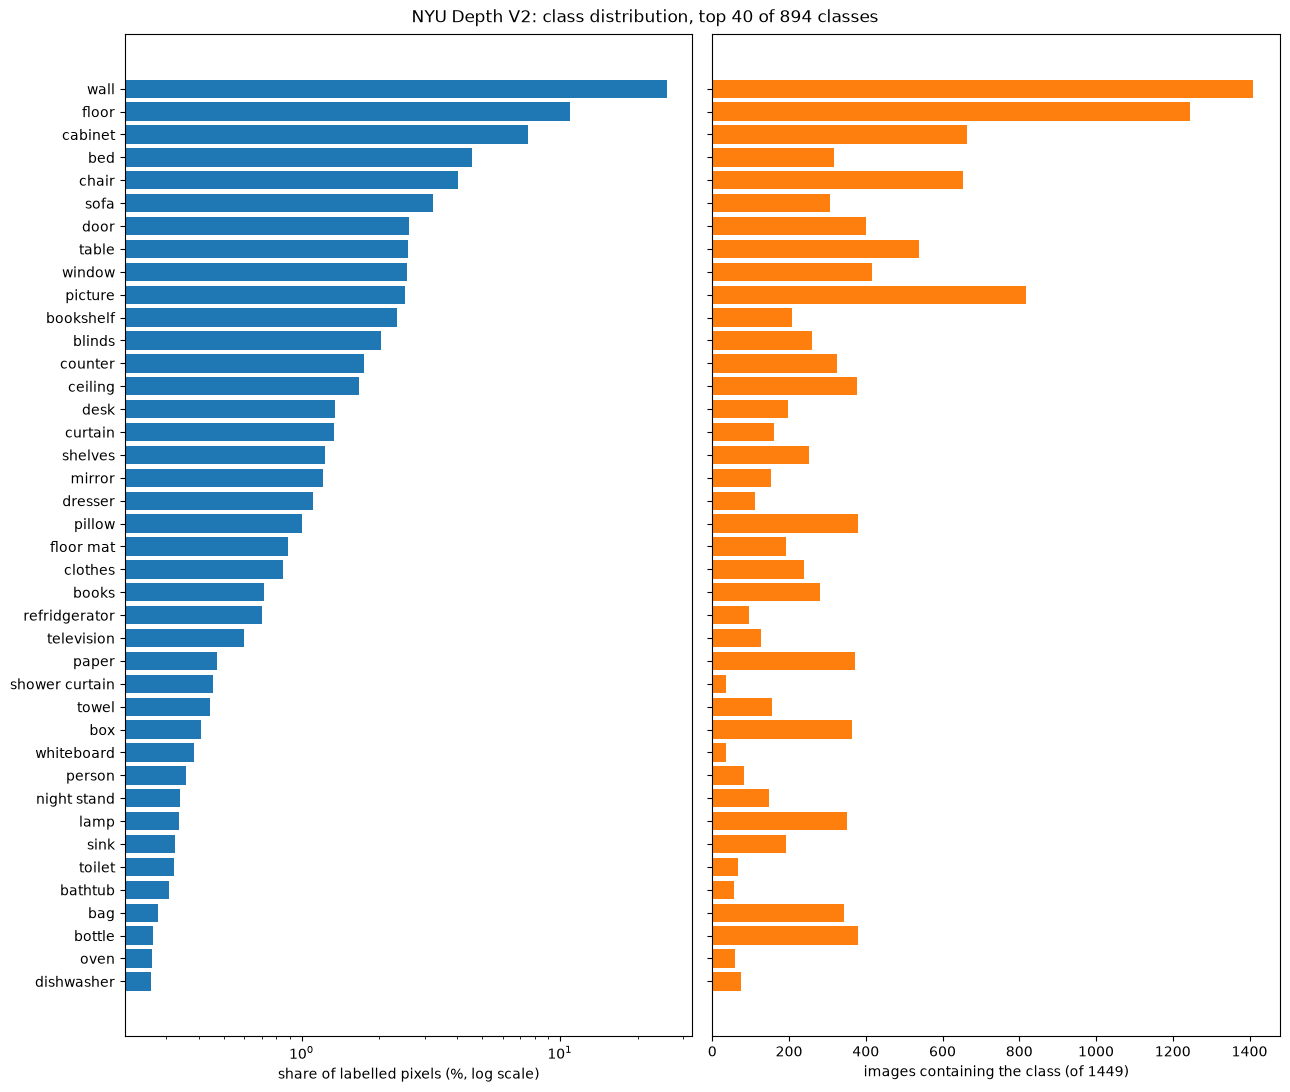

In [6]:
plot_class_distribution("nyu_depth_v2", top=40)

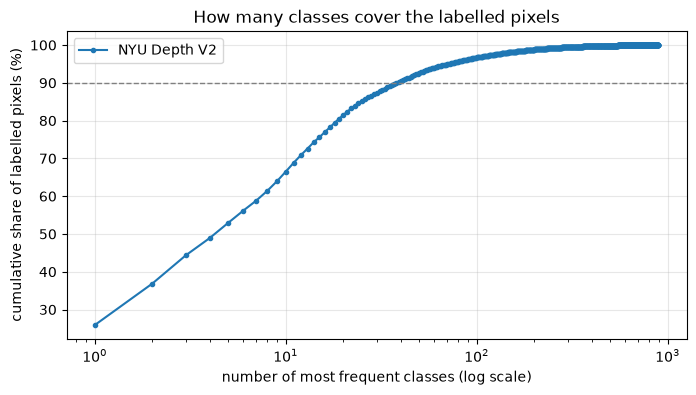

| Rank | Id | Class | Pixel share | Images | Instances | Instances / image |
|---|---|---|---|---|---|---|
| 1 | 21 | wall | 25.90% | 1409 | 3681 | 2.6 |
| 2 | 11 | floor | 10.97% | 1246 | 1423 | 1.1 |
| 3 | 3 | cabinet | 7.51% | 664 | 1522 | 2.3 |
| 4 | 157 | bed | 4.56% | 318 | 358 | 1.1 |
| 5 | 5 | chair | 4.03% | 654 | 2075 | 3.2 |
| 6 | 83 | sofa | 3.24% | 307 | 495 | 1.6 |
| 7 | 28 | door | 2.62% | 400 | 511 | 1.3 |
| 8 | 19 | table | 2.59% | 539 | 726 | 1.3 |
| 9 | 59 | window | 2.57% | 417 | 617 | 1.5 |
| 10 | 64 | picture | 2.52% | 818 | 2421 | 3.0 |
| 11 | 88 | bookshelf | 2.34% | 207 | 276 | 1.3 |
| 12 | 80 | blinds | 2.02% | 259 | 345 | 1.3 |
| 13 | 7 | counter | 1.74% | 324 | 430 | 1.3 |
| 14 | 4 | ceiling | 1.66% | 378 | 482 | 1.3 |
| 15 | 36 | desk | 1.34% | 197 | 357 | 1.8 |
| 16 | 89 | curtain | 1.34% | 161 | 247 | 1.5 |
| 17 | 42 | shelves | 1.23% | 253 | 426 | 1.7 |
| 18 | 122 | mirror | 1.21% | 153 | 242 | 1.6 |
| 19 | 169 | dresser | 1.11% | 111 | 123 | 1.1 |
| 20 | 119 | pillow | 1.00% | 380 | 1046 | 2.8 |

In [7]:
plot_class_coverage(["nyu_depth_v2"])
class_table("nyu_depth_v2", top=20)

In [8]:
lab = stats["nyu_depth_v2"]["labels"]
per_class = lab["per_class"]
print(f"Classes: {lab['num_classes']}, unlabeled pixels: {lab['background_ratio']:.1%}")
print(f"Classes covering 90% of labelled pixels: {lab['imbalance']['classes_for_90pct_pixels']}")
for k in (10, 50):
    print(f"Classes present in at least {k} images: {sum(c['images'] >= k for c in per_class)}")
print(f"Rare classes (<0.1% of pixels or <10 images): {len(lab['imbalance']['rare_classes'])}")
print(f"Classes per image: mean {lab['per_image']['classes']['mean']:.1f}, "
      f"instances per image: mean {lab['per_image']['instances']['mean']:.1f}")

Classes: 894, unlabeled pixels: 17.4%
Classes covering 90% of labelled pixels: 39
Classes present in at least 10 images: 177
Classes present in at least 50 images: 75
Rare classes (<0.1% of pixels or <10 images): 834
Classes per image: mean 14.1, instances per image: mean 24.2


**Reading the distribution.** The class distribution is extremely long-tailed. `wall` and `floor`
alone are about 37 % of the labelled pixels, 39 classes cover 90 %, and only 177 of the 894 classes
appear in at least 10 images. 834 classes count as rare. A model trained on all 894 classes would
see most of them a handful of times, so the label set has to be reduced (e.g. to the standard
40 classes) before training.

### 1.5 Suitable tasks

| Task | Suitable? | Why |
|---|---|---|
| Semantic segmentation | yes, main use | dense per-pixel labels, standard benchmark split |
| Instance segmentation | yes | instance ids per object |
| Monocular depth estimation | yes | aligned metric depth for every RGB frame |
| Depth completion | yes | raw and filled depth for the same frame |
| Scene classification | limited | 27 scene types, but few samples for the small ones |
| 2D object detection | only with derived boxes | boxes must be computed from instance masks |
| 3D object detection | no | no 3D boxes in this dataset (SUN RGB-D adds them for the same frames) |

### 1.6 Data quality

In [9]:
show_quality("nyu_depth_v2")

| Check | Issue | Samples | Examples |
|---|---|---|---|
| structure | missing files | 0 |  |
| structure | unreadable files | 0 |  |
| structure | incomplete samples | 0 |  |
| structure | duplicate ids / paths | 0 |  |
| rgb | dark | 2 | nyu_000386, nyu_000644 |
| rgb | bright | 0 |  |
| rgb | low contrast | 0 |  |
| rgb | bad channels | 0 |  |
| rgb | unreadable | 0 |  |
| depth | unreadable | 0 |  |
| depth | bad format | 0 |  |
| depth | empty | 0 |  |
| depth | low valid | 56 | nyu_000014, nyu_000117, nyu_000121 |
| depth | constant | 0 |  |
| labels | unreadable | 0 |  |
| labels | bad format | 0 |  |
| labels | bad values | 0 |  |
| labels | unlabeled | 0 |  |
| alignment | unreadable | 0 |  |
| alignment | size mismatch | 0 |  |
| alignment | misaligned | 0 |  |
| alignment | duplicate | 0 |  |
| alignment | near-duplicate train/test pairs | 0 |  |

**Exclusion candidates:** 58 of 1449 samples (4.0%); by check: depth: 56, rgb: 2. The full list is in `data/reports/problematic_samples.jsonl`.

- **Completeness:** all 1449 samples have all five files, nothing is unreadable, no duplicates
  and no near-duplicates between train and test.
- **Depth holes:** 31 % of the raw depth pixels are missing (reflective, dark or far surfaces
  and the sensor shadow). The filled depth has no holes, but those values are in-painted, not
  measured. 56 frames have less than half of their raw depth measured.
- **Alignment:** RGB and depth edges match without shifting in 97.5 % of the frames, so the
  pairs are well registered.
- **Imbalance:** see 1.4. In addition, 11 scene types appear only in the training split, so
  the test split covers a narrower set of scenes.
- **Dark images:** 2 frames have very low brightness.

### 1.7 Analysis

**Why this data is good.**
Real indoor scenes captured with a real depth sensor, densely labeled by hand at pixel level,
with an RGB and a depth map that are well registered. It has an official, widely used
train/test split, so results are comparable with the literature.

**Why we use it.**
It is the standard indoor RGB-D segmentation benchmark and is easy to obtain (one 2.8 GB file,
no registration). Alternatives we considered:
ScanNet (much larger, but requires a signed terms-of-use agreement and over 1 TB of data),
Matterport3D (also requires an agreement), Hypersim (synthetic, so a domain gap to real
sensors), and COCO / ADE20K (large, but no depth). NYU gives real RGB-D data with dense labels
at a size we can handle.

**What it is not enough for.**
- *Size:* 795 training frames are too few to train a deep model from scratch.
- *Diversity:* one sensor (Kinect v1), mostly homes in three US cities, 2011-era image quality.
  Models may not generalize to other sensors or environments.
- *Labels:* 894 free-text classes with a very long tail; most classes are unusable without
  merging.
- *Detection:* no bounding boxes, no 3D annotation.
- *Depth:* about a third of the raw depth is missing; the filled values are estimates.

**What decisions it supports.**
- Use a **pretrained backbone** and fine-tune, rather than training from scratch.
- **Reduce the label set** (e.g. the standard 40-class mapping) and use a class-balanced loss
  or weighting for the remaining imbalance.
- Feed **depth as an extra input channel** and prefer the filled depth for input, but evaluate
  depth tasks only on raw (measured) pixels.
- Report results on the **official test split** so they are comparable.
- NYU alone is too small: combine it with SUN RGB-D (section 2), which contains these 1449
  frames as a subset.

## 2. SUN RGB-D

### 2.1 What the data is

**SUN RGB-D** (Song, Lichtenberg and Xiao, *SUN RGB-D: A RGB-D Scene Understanding Benchmark
Suite*, CVPR 2015) contains **10335 RGB-D images** of indoor scenes, captured with **four
different depth sensors**: Kinect v1, Kinect v2, Intel RealSense and Asus Xtion. Part of it
was recorded by the authors; the rest was collected from earlier datasets (NYU Depth V2,
Berkeley B3DO, SUN3D) and re-annotated in one consistent way.

Modalities after our preparation step (`data/processed/sunrgbd/`):

- **RGB**: 8-bit JPEG, copied from the original without re-encoding. The resolution depends on the sensor.
- **Depth, filled**: millimetres as 16-bit PNG (from the dataset's `depth_bfx` maps, where the
  holes are filled), decoded from SUN's bit-rotated storage format.
- **Depth, raw**: the original sensor measurement, 0 means "no measurement".
- **Semantic labels**: the standard **37-class** labels (0 = unlabeled), 8-bit PNG.
- **Instance map**: object ids within the image, 16-bit PNG.
- Metadata in `index.jsonl`: split, scene type, sensor and the original source folder.
- **2D and 3D bounding boxes** in the toolbox metadata (`SUNRGBDMeta2DBB_v2.mat`, `SUNRGBDMeta3DBB_v2.mat`).

In [10]:
show_overview("sunrgbd")
show_depth_summary("sunrgbd")

| Modality | Index field | Format | dtype | Resolution W×H (samples) |
|---|---|---|---|---|
| RGB image | `rgb` | JPEG | uint8 | 730x530 (3784), 591x441 (3389), 561x427 (2003), 681x531 (1159) |
| Depth, filled | `depth` | PNG | uint16 | 730x530 (3784), 591x441 (3389), 561x427 (2003), 681x531 (1159) |
| Depth, raw sensor | `depth_raw` | PNG | uint16 | 730x530 (3784), 591x441 (3389), 561x427 (2003), 681x531 (1159) |
| Semantic label map | `semantic` | PNG | uint8 | 730x530 (3784), 591x441 (3389), 561x427 (2003), 681x531 (1159) |
| Instance map | `instance` | PNG | uint16 | 730x530 (3784), 591x441 (3389), 561x427 (2003), 681x531 (1159) |

| Samples | Train | Test | Train share | Download size | Processed size | Processed files |
|---|---|---|---|---|---|---|
| 10335 | 5285 | 5050 | 51.1% | 7.0 GiB | 3.1 GiB | 51677 |

| Depth map | Min (m) | P1 (m) | Median (m) | P99 (m) | Max (m) | Missing pixels | Worst sample: valid pixels |
|---|---|---|---|---|---|---|---|
| Depth, filled | 0.35 | 0.68 | 2.08 | 6.99 | 10.00 | 0.0% | 100.0% |
| Depth, raw sensor | 0.35 | 0.73 | 2.04 | 6.38 | 10.00 | 17.4% | 30.6% |

Where the images come from: sensor and original source folder (from the `source` field of the index).

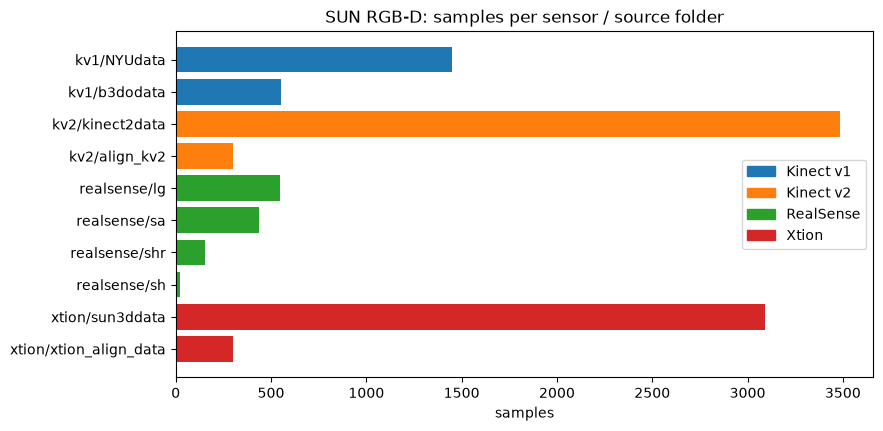

In [11]:
sources = {}
for row in index["sunrgbd"]:
    key = "/".join(row["source"].split("/")[1:3])  # e.g. kv2/kinect2data
    sources[key] = sources.get(key, 0) + 1
items = sorted(sources.items(), key=lambda kv: (kv[0].split("/")[0], -kv[1]))[::-1]
sensor_names = {"kv1": "Kinect v1", "kv2": "Kinect v2", "realsense": "RealSense", "xtion": "Xtion"}
colors = dict(zip(sensor_names, plt.get_cmap("tab10").colors))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([k for k, _ in items], [v for _, v in items], color=[colors[k.split("/")[0]] for k, _ in items])
ax.set_xlabel("samples")
ax.set_title("SUN RGB-D: samples per sensor / source folder")
ax.legend(handles=[Patch(color=colors[s], label=n) for s, n in sensor_names.items()])
plt.show()

Four random samples. Note the different image sizes and the different look of the sensors.

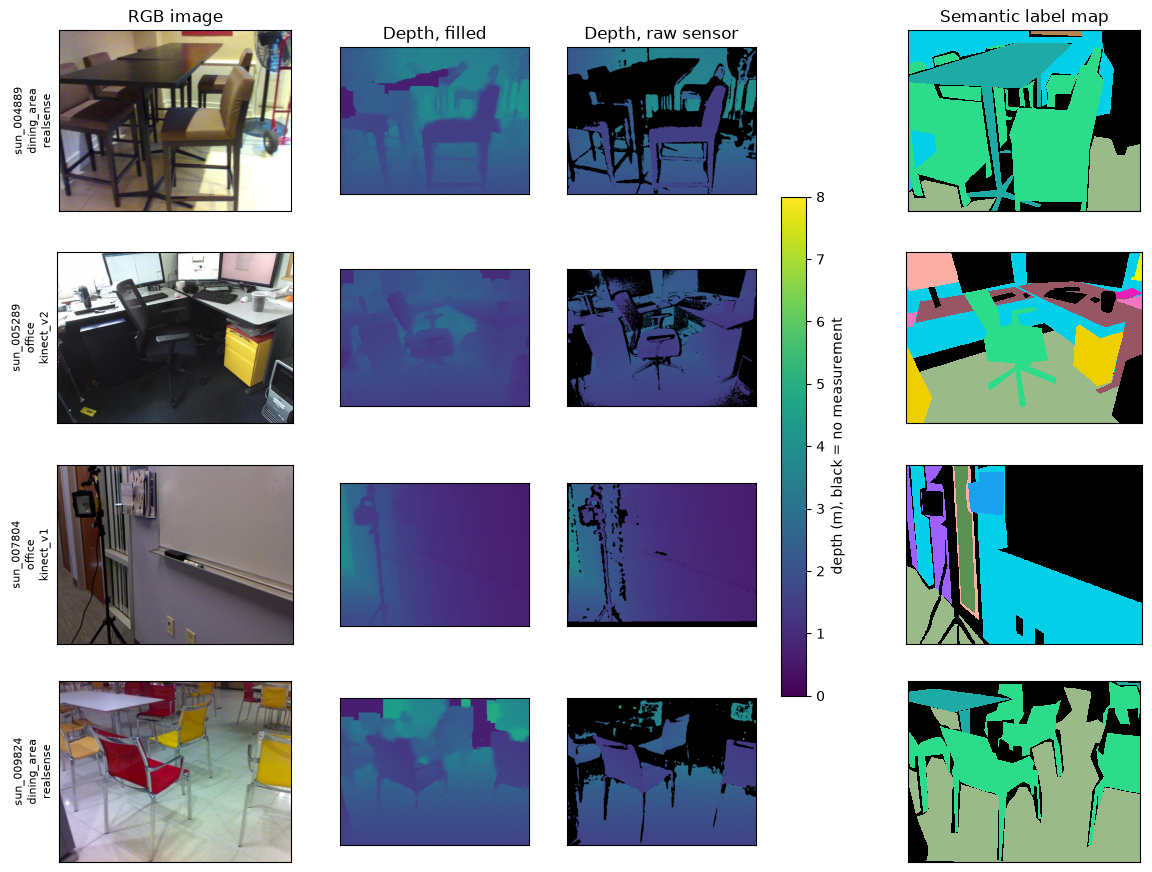

In [12]:
show_samples("sunrgbd", seed=1)

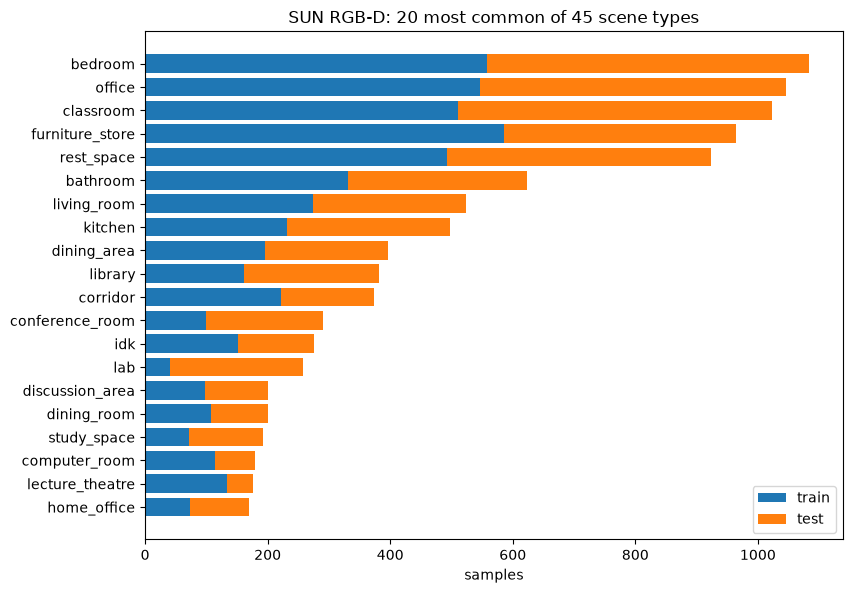

In [13]:
plot_scenes("sunrgbd")

### 2.2 Source and download

- **Official page:** https://rgbd.cs.princeton.edu/
- **Files we use** (URLs, sizes and SHA-256 hashes are pinned in `data/manifests/datasets.json`):
  - `SUNRGBD.zip` (6.4 GB): the images, depth maps and per-image annotation folders.
  - `SUNRGBDtoolbox.zip` (0.5 GB): the official train/test split (`allsplit.mat`), the metadata
    (`SUNRGBDMeta.mat`) and the 37-class segmentation labels (`SUNRGBD2Dseg.mat`).
  - `SUNRGBDMeta2DBB_v2.mat` and `SUNRGBDMeta3DBB_v2.mat`: the 2D and 3D bounding boxes.
- **How we download it:** `python data/scripts/collect_data.py --datasets sunrgbd`. Same
  procedure as for NYU: resumable download, size and SHA-256 check, safe ZIP extraction (path
  traversal check) into `raw/` (never modified afterwards), dataset verification, then
  conversion into `processed/sunrgbd/` with `index.jsonl` and `classes.json`.

### 2.3 Use in the project

- **Data exploration:** this notebook and `data/reports/data_evaluation.md`.
- **Training:** the main training set. It is 7 times larger than NYU, covers four sensors and
  has both segmentation labels and bounding boxes, so it serves **both stages of the pipeline**:
  detection (2D boxes, optionally 3D) and segmentation (37 classes).
- **Evaluation:** the official 5050-image test split; the 37-class segmentation and the 3D
  detection benchmarks of SUN RGB-D are standard in the literature.

### 2.4 Labels and class distribution

- **Semantic labels:** 37 object classes (`wall`, `floor`, `cabinet`, `bed`, `chair`, ...),
  plus 0 = unlabeled. This is the official benchmark label set from the toolbox.
- **Instance labels:** object ids per image, from the per-image `seg.mat` annotations.
- **2D bounding boxes:** 80 220 boxes, 7.8 per image on average.
- **3D bounding boxes:** 64 657 oriented boxes in metres, 6.3 per image on average.
- **Scene label:** 45 scene types (including `idk`, "unknown").

The class distribution of the 37 segmentation classes (all classes shown):

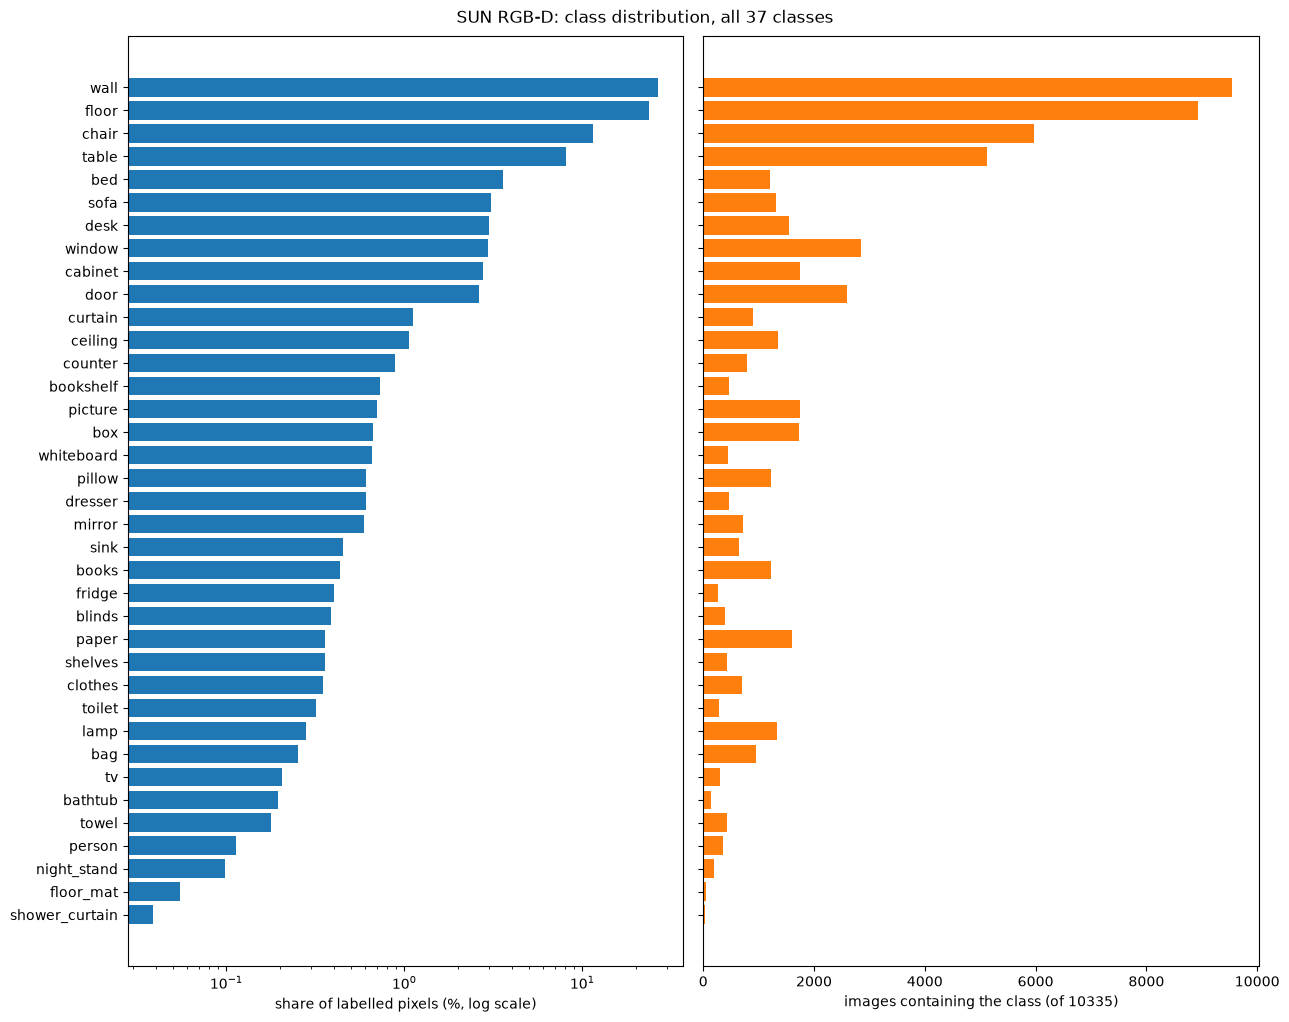

In [14]:
plot_class_distribution("sunrgbd")

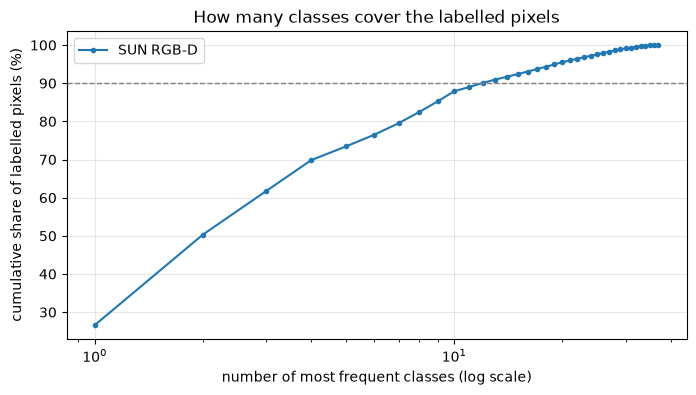

| Rank | Id | Class | Pixel share | Images | Instances | Instances / image |
|---|---|---|---|---|---|---|
| 1 | 1 | wall | 26.62% | 9553 | 22895 | 2.4 |
| 2 | 2 | floor | 23.72% | 8937 | 15741 | 1.8 |
| 3 | 5 | chair | 11.41% | 5964 | 25690 | 4.3 |
| 4 | 7 | table | 8.08% | 5120 | 10051 | 2.0 |
| 5 | 4 | bed | 3.60% | 1208 | 1946 | 1.6 |
| 6 | 6 | sofa | 3.09% | 1310 | 2457 | 1.9 |
| 7 | 14 | desk | 2.99% | 1546 | 3696 | 2.4 |
| 8 | 9 | window | 2.96% | 2847 | 5011 | 1.8 |
| 9 | 3 | cabinet | 2.78% | 1738 | 3556 | 2.0 |
| 10 | 8 | door | 2.64% | 2596 | 3973 | 1.5 |
| 11 | 16 | curtain | 1.11% | 903 | 1291 | 1.4 |
| 12 | 22 | ceiling | 1.07% | 1346 | 1688 | 1.3 |
| 13 | 12 | counter | 0.88% | 794 | 1084 | 1.4 |
| 14 | 10 | bookshelf | 0.73% | 463 | 689 | 1.5 |
| 15 | 11 | picture | 0.70% | 1755 | 4163 | 2.4 |
| 16 | 29 | box | 0.67% | 1734 | 3452 | 2.0 |
| 17 | 30 | whiteboard | 0.66% | 449 | 546 | 1.2 |
| 18 | 18 | pillow | 0.61% | 1226 | 3356 | 2.7 |
| 19 | 17 | dresser | 0.61% | 464 | 777 | 1.7 |
| 20 | 19 | mirror | 0.60% | 716 | 954 | 1.3 |
| 21 | 34 | sink | 0.45% | 638 | 786 | 1.2 |
| 22 | 23 | books | 0.44% | 1217 | 4098 | 3.4 |
| 23 | 24 | fridge | 0.40% | 275 | 321 | 1.2 |
| 24 | 13 | blinds | 0.39% | 391 | 528 | 1.4 |
| 25 | 26 | paper | 0.36% | 1611 | 3401 | 2.1 |
| 26 | 15 | shelves | 0.36% | 429 | 709 | 1.7 |
| 27 | 21 | clothes | 0.35% | 707 | 1181 | 1.7 |
| 28 | 33 | toilet | 0.32% | 283 | 319 | 1.1 |
| 29 | 35 | lamp | 0.28% | 1340 | 2150 | 1.6 |
| 30 | 37 | bag | 0.25% | 958 | 1371 | 1.4 |
| 31 | 25 | tv | 0.20% | 296 | 336 | 1.1 |
| 32 | 36 | bathtub | 0.19% | 145 | 163 | 1.1 |
| 33 | 27 | towel | 0.18% | 432 | 663 | 1.5 |
| 34 | 31 | person | 0.11% | 349 | 583 | 1.7 |
| 35 | 32 | night_stand | 0.10% | 186 | 251 | 1.3 |
| 36 | 20 | floor_mat | 0.05% | 54 | 72 | 1.3 |
| 37 | 28 | shower_curtain | 0.04% | 30 | 30 | 1.0 |

In [15]:
plot_class_coverage(["sunrgbd"])
class_table("sunrgbd")

In [16]:
lab = stats["sunrgbd"]["labels"]
print(f"Classes: {lab['num_classes']}, unlabeled pixels: {lab['background_ratio']:.1%}")
print(f"Classes covering 90% of labelled pixels: {lab['imbalance']['classes_for_90pct_pixels']}")
print(f"Most / least frequent class pixel ratio: {lab['imbalance']['max_min_pixel_ratio']:.0f}x")
print(f"Rare classes: {', '.join(lab['imbalance']['rare_classes'])}")
print(f"Classes per image: mean {lab['per_image']['classes']['mean']:.1f}, "
      f"instances per image: mean {lab['per_image']['instances']['mean']:.1f}")

Classes: 37, unlabeled pixels: 25.0%
Classes covering 90% of labelled pixels: 12
Most / least frequent class pixel ratio: 688x
Rare classes: floor_mat, shower_curtain, night_stand
Classes per image: mean 5.8, instances per image: mean 12.6


Bounding box labels. The box names are free text (over 1000 distinct names), so the table shows
the most frequent ones; a detector needs a fixed class list chosen from these.

| Boxes | Images | Total | Per image (mean / max) | Distinct names | Invalid | Partly outside image |
|---|---|---|---|---|---|---|
| 2D | 10335 | 80220 | 7.8 / 49 | 1068 | 0 | 2453 |
| 3D | 10335 | 64657 | 6.3 / 46 | 1143 | 8 | - |

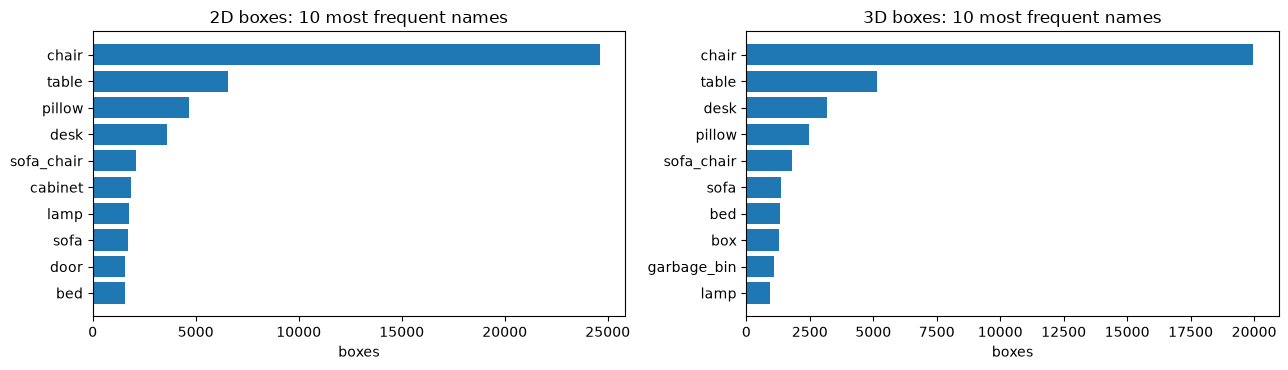

In [17]:
boxes = stats["sunrgbd"]["labels"]["boxes"]
md_table(
    ["Boxes", "Images", "Total", "Per image (mean / max)", "Distinct names", "Invalid", "Partly outside image"],
    [[kind.upper(), b["images"], b["boxes"], f"{b['per_image']['mean']:.1f} / {b['per_image']['max']:.0f}",
      b["distinct_names"], b["invalid"], b.get("outside_image", "-")] for kind, b in boxes.items()],
)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (kind, b) in zip(axes, boxes.items()):
    names = list(b["top_names"])[::-1]
    ax.barh(names, [b["top_names"][n] for n in names])
    ax.set_title(f"{kind.upper()} boxes: 10 most frequent names")
    ax.set_xlabel("boxes")
fig.tight_layout()
plt.show()

**Reading the distribution.** With 37 classes the imbalance is much milder than in NYU, but still
large: `wall`, `floor`, `chair` and `table` together are about 70 % of the labelled pixels, 12
classes cover 90 %, and the most frequent class has about 690 times more pixels than the least
frequent one (`shower_curtain`). Every class appears in at least 30 images, so all 37 are
learnable, but the small classes need weighting. For detection, `chair` alone is about 30 % of
all 2D and 3D boxes.

#### 3D bounding boxes (training targets)

The 3D boxes are exported next to the segmentation maps, so a detector can be trained from the
same `index.jsonl`: `processed/sunrgbd/boxes3d.jsonl` has one line per sample (same `id`, all
splits) with the camera intrinsics `K`, the tilt rotation `Rtilt` and the list of boxes. Each box
has a `classname`, a `centroid` and a full `size` in metres and a `basis` (rotation around the
vertical axis). The boxes live in the upright coordinate system of the SUN RGB-D toolbox (z up);
`Rtilt` and `K` project them back into the image. NYU Depth V2 has no 3D annotation, so it has no
such file.

Boxes per split and per image (the validation set is the part of the official train set that
`val_ratio` selects):

In [ ]:
def load_boxes3d(name: str = "sunrgbd") -> dict[str, dict]:
    path = DATA_ROOT / "processed" / name / "boxes3d.jsonl"
    with path.open(encoding="utf-8") as f:
        return {r["id"]: r for r in map(json.loads, f) if r}


boxes3d = load_boxes3d()
split_of = {r["id"]: r["split"] for r in index["sunrgbd"]}
rows = []
for split in ("train", "val", "test"):
    per_image = [len(boxes3d[i]["boxes"]) for i, s in split_of.items() if s == split]
    rows.append([split, len(per_image), sum(per_image), f"{np.mean(per_image):.1f} / {max(per_image)}",
                 sum(n == 0 for n in per_image)])
md_table(["Split", "Images", "3D boxes", "Per image (mean / max)", "Images without a box"], rows)

| Split | Images | 3D boxes | Per image (mean / max) | Images without a box |
|---|---|---|---|---|
| train | 4757 | 29327 | 6.2 / 32 | 17 |
| val | 528 | 3160 | 6.0 / 28 | 5 |
| test | 5050 | 32170 | 6.4 / 46 | 22 |

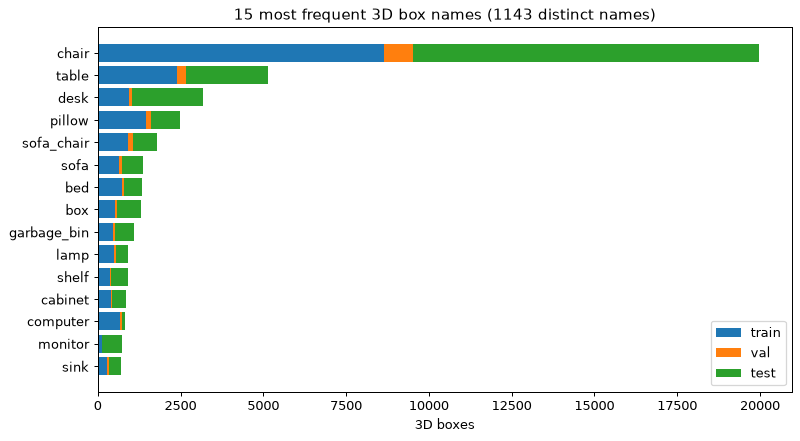

| Name | Boxes | Median size x / y / z (m, z = height) |
|---|---|---|
| chair | 19964 | 0.55 / 0.58 / 0.83 |
| table | 5132 | 1.28 / 0.80 / 0.73 |
| desk | 3193 | 1.26 / 0.62 / 0.75 |
| pillow | 2478 | 0.54 / 0.35 / 0.33 |
| sofa_chair | 1792 | 0.83 / 0.82 / 0.82 |
| sofa | 1366 | 1.84 / 0.91 / 0.84 |
| bed | 1342 | 1.59 / 2.11 / 0.96 |
| box | 1305 | 0.36 / 0.35 / 0.29 |
| garbage_bin | 1085 | 0.38 / 0.35 / 0.49 |
| lamp | 928 | 0.39 / 0.37 / 0.73 |

In [ ]:
from collections import Counter

names = Counter(b["classname"] for r in boxes3d.values() for b in r["boxes"])
top = [n for n, _ in names.most_common(15)][::-1]
per_split = {s: Counter(b["classname"] for i, r in boxes3d.items() if split_of[i] == s for b in r["boxes"])
             for s in ("train", "val", "test")}

fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(top))
for s, counts in per_split.items():
    values = np.array([counts[n] for n in top])
    ax.barh(top, values, left=left, label=s)
    left += values
ax.set_xlabel("3D boxes")
ax.set_title(f"15 most frequent 3D box names ({len(names)} distinct names)")
ax.legend()
fig.tight_layout()
plt.show()

sizes = {n: np.array([b["size"] for r in boxes3d.values() for b in r["boxes"] if b["classname"] == n]) for n in top[::-1][:10]}
md_table(
    ["Name", "Boxes", "Median size x / y / z (m, z = height)"],
    [[n, len(s), " / ".join(f"{v:.2f}" for v in np.median(s, axis=0))] for n, s in sizes.items()],
)

**Reading the 3D boxes.** The box names are free text and extremely long-tailed: 1143 distinct names, and `chair` alone is about 31 % of the 64 657 boxes. A detector therefore needs a fixed class list chosen from the most frequent names. The sizes are plausible (a chair is about 0.55 × 0.58 × 0.83 m, a bed 1.59 × 2.11 × 0.96 m), and 44 images have no box at all. The splits are the same as for segmentation (validation is a random part of train).

The next figure projects the exported boxes back into three random images (four or more boxes each), which also checks the coordinate conventions: the boxes line up with their objects.

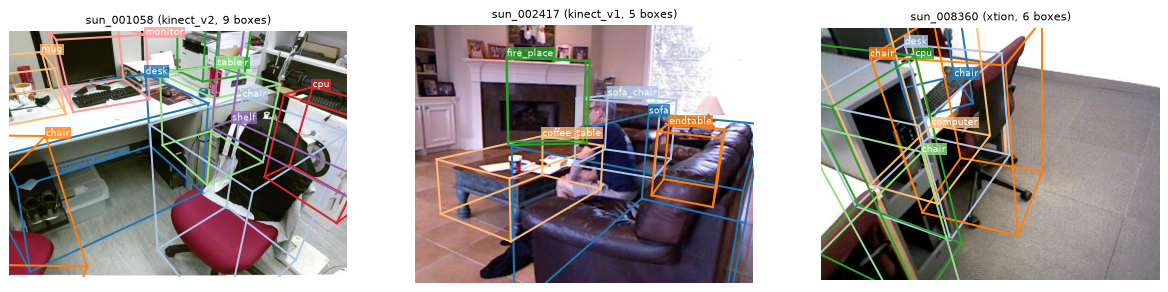

In [ ]:
BOX_EDGES = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]
BOX_SIGNS = np.array([[-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
                      [-1, -1, 1], [1, -1, 1], [1, 1, 1], [-1, 1, 1]])


def project_box(box: dict, sample: dict) -> np.ndarray:
    """Eight corners of a 3D box in pixels (NaN where the corner is behind the camera)."""
    corners = np.array(box["centroid"]) + (BOX_SIGNS * np.array(box["size"]) / 2) @ np.array(box["basis"])
    x3, z, minus_y3 = (corners @ np.array(sample["Rtilt"])).T  # upright system -> camera points
    fx, fy, cx, cy = (sample["K"][0][0], sample["K"][1][1], sample["K"][0][2], sample["K"][1][2])
    with np.errstate(divide="ignore", invalid="ignore"):
        u = np.where(z > 0.1, x3 * fx / z + cx - 1, np.nan)
        v = np.where(z > 0.1, -minus_y3 * fy / z + cy - 1, np.nan)
    return np.stack([u, v], axis=1)


def show_boxes3d(n: int = 3, seed: int = 2, min_boxes: int = 4) -> None:
    rows = [r for r in index["sunrgbd"] if len(boxes3d[r["id"]]["boxes"]) >= min_boxes]
    picks = [rows[i] for i in sorted(np.random.default_rng(seed).choice(len(rows), n, replace=False))]
    colors = plt.get_cmap("tab20")
    fig, axes = plt.subplots(1, n, figsize=(5.5 * n, 4.6))
    for ax, row in zip(np.atleast_1d(axes), picks):
        sample = boxes3d[row["id"]]
        image = Image.open(DATA_ROOT / "processed" / "sunrgbd" / row["rgb"])
        width, height = image.size
        ax.imshow(image)
        for k, box in enumerate(sample["boxes"]):
            pts = project_box(box, sample)
            for a, b in BOX_EDGES:
                ax.plot(pts[[a, b], 0], pts[[a, b], 1], color=colors(k % 20), lw=1.6)
            visible = pts[np.isfinite(pts).all(axis=1)]
            visible = visible[(visible[:, 0] > 0) & (visible[:, 0] < width) & (visible[:, 1] > 0) & (visible[:, 1] < height)]
            if len(visible):  # label at the highest corner that is inside the image
                ax.text(*visible[np.argmin(visible[:, 1])], box["classname"], color="white", fontsize=7,
                        bbox=dict(facecolor=colors(k % 20), alpha=0.8, pad=1, lw=0))
        ax.set_title(f"{row['id']} ({row['sensor']}, {len(sample['boxes'])} boxes)", fontsize=9)
        ax.set_xlim(0, width)
        ax.set_ylim(height, 0)
        ax.axis("off")
    plt.show()


show_boxes3d()

### 2.5 Suitable tasks

| Task | Suitable? | Why |
|---|---|---|
| Semantic segmentation | yes, main use | 37 standard classes, 10k images, official split |
| 2D object detection | yes | 80k 2D boxes (class list must be fixed from free-text names) |
| 3D object detection | yes | 64k oriented 3D boxes with camera intrinsics and tilt, exported to `boxes3d.jsonl` |
| Instance segmentation | yes | instance ids per object |
| Monocular depth estimation | yes | metric depth from four sensors |
| Scene classification | yes | 45 scene types, ~1000 images for the largest ones |

### 2.6 Data quality

In [18]:
show_quality("sunrgbd")

| Check | Issue | Samples | Examples |
|---|---|---|---|
| structure | missing files | 0 |  |
| structure | unreadable files | 0 |  |
| structure | incomplete samples | 0 |  |
| structure | duplicate ids / paths | 0 |  |
| rgb | dark | 34 | sun_001921, sun_002010, sun_002012 |
| rgb | bright | 0 |  |
| rgb | low contrast | 0 |  |
| rgb | bad channels | 0 |  |
| rgb | unreadable | 0 |  |
| depth | unreadable | 0 |  |
| depth | bad format | 0 |  |
| depth | empty | 0 |  |
| depth | low valid | 372 | sun_000013, sun_000134, sun_000135 |
| depth | constant | 0 |  |
| labels | unreadable | 0 |  |
| labels | bad format | 0 |  |
| labels | bad values | 0 |  |
| labels | unlabeled | 3 | sun_005407, sun_008010, sun_008104 |
| labels | bad box 2d | 0 |  |
| labels | bad box 3d | 8 | sun_002094, sun_007334, sun_007446 |
| alignment | unreadable | 0 |  |
| alignment | size mismatch | 0 |  |
| alignment | misaligned | 238 | sun_001055, sun_001155, sun_001363 |
| alignment | duplicate | 0 |  |
| alignment | near-duplicate train/test pairs | 0 |  |

**Exclusion candidates:** 652 of 10335 samples (6.3%); by check: alignment: 238, depth: 372, rgb: 34, labels: 11. The full list is in `data/reports/problematic_samples.jsonl`.

- **Completeness:** all 10335 samples have all five files, nothing is unreadable, no exact or
  near duplicates within or across the splits.
- **Mixed resolutions:** four image sizes from 561×427 to 730×530 (one per sensor), so inputs
  must be resized or cropped to a common size.
- **Depth holes:** 17 % of the raw depth pixels are missing; 372 images have less than half of
  their raw depth measured.
- **RGB-depth alignment:** the edge-based check finds a shift of 2 px or more in many images,
  most often for Xtion, Kinect v1 and RealSense; 238 images are flagged as misaligned. Kinect v2
  is the best registered sensor.
- **Labels:** 3 images have no labelled pixel at all, 8 have invalid 3D boxes, and 2453 2D boxes
  reach partly outside the image (they need clipping).
- **Dark images:** 34.
- **Overlap with NYU:** the 1449 `kv1/NYUdata` images are the NYU Depth V2 labeled frames, with
  the same train/test assignment (checked by the evaluator, see section 3).
- **Splits:** 3 scene types appear only in train, 1 only in test.

### 2.7 Analysis

**Why this data is good.**
It is the largest real, densely labeled indoor RGB-D dataset that is freely downloadable.
Four sensors and many environments (homes, offices, classrooms, shops, libraries) give much
more variety than NYU. It has **all the label types our pipeline needs on the same images**:
per-pixel classes for segmentation and 2D/3D boxes for detection, with an official split.

**Why we use it.**
It is the standard benchmark for indoor RGB-D segmentation and 3D detection, and it already
includes NYU, so the two datasets fit together. Alternatives considered: ScanNet (larger, but
video-based, needs a terms-of-use agreement and over 1 TB), Matterport3D (needs an agreement),
Hypersim (synthetic), COCO / ADE20K (no depth). SUN RGB-D is the best balance of size, label
richness and accessibility.

**What it is not enough for.**
- *Size:* 10k images is still small compared to RGB datasets like COCO (over 100k), so
  pretraining remains necessary.
- *Sensor differences:* four sensors with different resolutions, depth noise and registration
  quality; a model can learn sensor-specific cues, and the alignment is not perfect for all sensors.
- *Labels:* only 37 segmentation classes, so the "prompt" part of the pipeline cannot ask for
  arbitrary objects; box names are free text and need cleaning into a fixed class list.
- *Domain:* indoor scenes only, no outdoor or people-centric data.
- *Exclusions:* about 6 % of the images are flagged by at least one quality check.

**What decisions it supports.**
- Use SUN RGB-D as the **main training set** and its 37 classes as the common label space.
- **Resize / crop** every input to one resolution and **normalize per sensor** or augment
  across sensors; report results per sensor too.
- Use the **2D boxes** (clipped to the image, mapped to a fixed class list) for the detection
  stage and the **37-class masks** for the segmentation stage.
- Use class-balanced loss or sampling for the rare classes (`floor_mat`, `shower_curtain`, `night_stand`).
- Drop or down-weight the flagged samples listed in `problematic_samples.jsonl`.

## 3. Overall analysis and comparison

### 3.1 Side by side

In [19]:
def row(label: str, fn) -> list:
    return [label] + [fn(stats[name]) for name in DATASETS]


def resolutions(d: dict) -> str:
    return ", ".join(d["structure"]["files"]["rgb"]["resolution"])


def boxes(d: dict) -> str:
    b = d["labels"]["boxes"]
    return f"2D: {b['2d']['boxes']}, 3D: {b['3d']['boxes']}" if isinstance(b, dict) else "none"


md_table(["Property"] + list(DATASETS.values()), [
    row("Samples (train / test)", lambda d: f"{d['structure']['samples']['total']} "
        f"({d['structure']['samples']['train']} / {d['structure']['samples']['test']})"),
    row("Sensors", lambda d: ", ".join(d["alignment"]["sensors"]["counts"])),
    row("RGB resolutions", resolutions),
    row("Scene types", lambda d: d["alignment"]["scenes"]["values"]),
    row("Segmentation classes", lambda d: d["labels"]["num_classes"]),
    row("Classes covering 90% of pixels", lambda d: d["labels"]["imbalance"]["classes_for_90pct_pixels"]),
    row("Rare classes", lambda d: len(d["labels"]["imbalance"]["rare_classes"])),
    row("Unlabeled pixels", lambda d: f"{d['labels']['background_ratio']:.1%}"),
    row("Objects per image (mean)", lambda d: f"{d['labels']['per_image']['instances']['mean']:.1f}"),
    row("Bounding boxes", boxes),
    row("Median depth (m)", lambda d: f"{d['depth']['depth']['valid_pixels']['median'] / 1000:.2f}"),
    row("Raw depth missing", lambda d: f"{d['depth']['depth_raw']['pixel_ratios']['invalid']:.1%}"),
    row("RGB-depth aligned without shift", lambda d: f"{d['alignment']['rgb_depth_alignment']['unshifted_ratio']:.1%}"),
    row("Exclusion candidates", lambda d: f"{d['alignment']['exclude_candidates']['samples']} "
        f"({d['alignment']['exclude_candidates']['samples'] / d['structure']['samples']['total']:.1%})"),
    row("Download size", lambda d: d["structure"]["disk_usage"]["downloads"]),
])

| Property | NYU Depth V2 | SUN RGB-D |
|---|---|---|
| Samples (train / test) | 1449 (795 / 654) | 10335 (5285 / 5050) |
| Sensors | kinect_v1 | kinect_v2, xtion, kinect_v1, realsense |
| RGB resolutions | 640x480 | 730x530, 561x427, 591x441, 681x531 |
| Scene types | 27 | 45 |
| Segmentation classes | 894 | 37 |
| Classes covering 90% of pixels | 39 | 12 |
| Rare classes | 834 | 3 |
| Unlabeled pixels | 17.4% | 25.0% |
| Objects per image (mean) | 24.2 | 12.6 |
| Bounding boxes | none | 2D: 80220, 3D: 64657 |
| Median depth (m) | 2.51 | 2.08 |
| Raw depth missing | 31.4% | 17.4% |
| RGB-depth aligned without shift | 97.5% | 33.8% |
| Exclusion candidates | 58 (4.0%) | 652 (6.3%) |
| Download size | 2.8 GiB | 7.0 GiB |

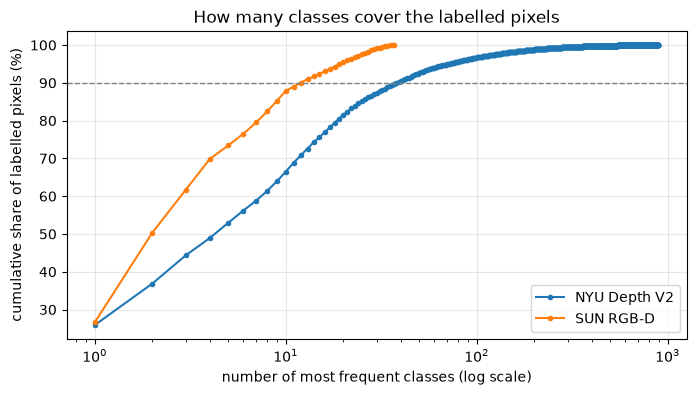

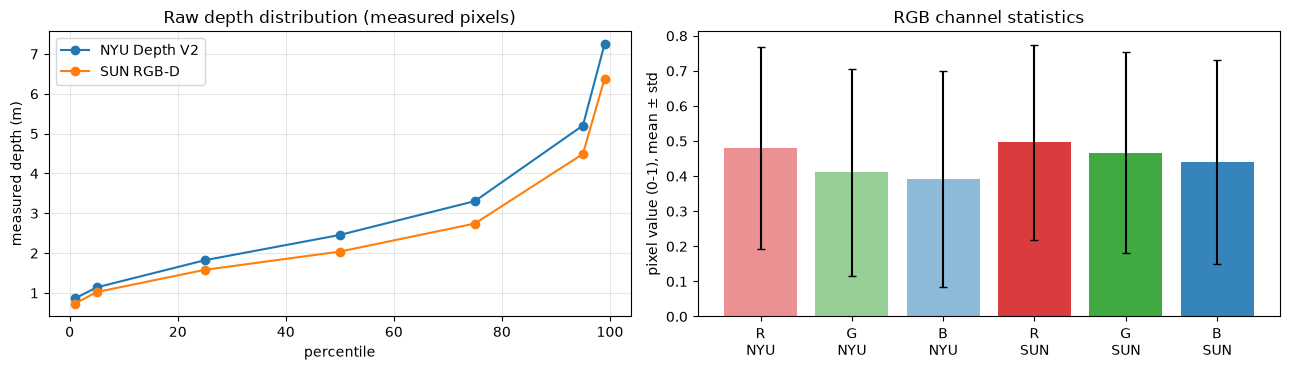

In [20]:
plot_class_coverage(list(DATASETS))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
levels = ["1", "5", "25", "50", "75", "95", "99"]
for name, title in DATASETS.items():
    p = stats[name]["depth"]["depth_raw"]["valid_pixels"]["percentiles"]
    axes[0].plot([int(k) for k in levels], [p[k] / 1000 for k in levels], marker="o", label=title)
    rgb = stats[name]["rgb"]["channels"]
    axes[1].bar([f"{c}\n{title.split()[0]}" for c in "RGB"], [rgb[c]["mean"] for c in "RGB"],
                yerr=[rgb[c]["std"] for c in "RGB"], color=["tab:red", "tab:green", "tab:blue"],
                alpha=0.9 if name == "sunrgbd" else 0.5, capsize=3)
axes[0].set_xlabel("percentile")
axes[0].set_ylabel("measured depth (m)")
axes[0].set_title("Raw depth distribution (measured pixels)")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].set_ylabel("pixel value (0-1), mean ± std")
axes[1].set_title("RGB channel statistics")
fig.tight_layout()
plt.show()

### 3.2 NYU Depth V2 is part of SUN RGB-D

In [21]:
ov = stats["sunrgbd"]["alignment"]["nyu_overlap"]
print(f"SUN RGB-D samples taken from NYU Depth V2: {ov['sun_samples_from_nyu']}")
print(f"Matched to an NYU frame: {ov['matched']}, with a different train/test split: {ov['split_differs']}")

SUN RGB-D samples taken from NYU Depth V2: 1449
Matched to an NYU frame: 1449, with a different train/test split: 0


All 1449 NYU frames are inside SUN RGB-D (`kv1/NYUdata`), with **the same train/test assignment**.
This has two consequences:

- **Do not simply concatenate the two datasets.** The NYU frames would be counted twice, with two
  different label sets (894 vs 37 classes) for the same pixels.
- **Training on SUN train and testing on NYU test is clean**: no NYU test frame is in SUN train, so
  NYU remains a valid separate benchmark.

### 3.3 Why these two datasets together

- **Complementary.** NYU is small but the classic, cleanly registered single-sensor benchmark with
  very fine-grained labels. SUN RGB-D is 7 times larger, has four sensors, a standard 37-class label
  set and 2D/3D boxes. Together they cover **every stage of our pipeline** (detection and
  segmentation) with real RGB-D data, plus a well-known benchmark for comparison.
- **Same domain and format.** Both are indoor scenes with metric depth from structured-light or
  time-of-flight sensors, converted by our pipeline into the same file layout, units (mm) and
  index format, so one data loader serves both.
- **Accessible and reproducible.** About 10 GB in total, no registration, pinned by SHA-256 in the
  manifest, downloadable with one command.

### 3.4 Common limitations and risks

| Limitation | Risk for the project | Mitigation |
|---|---|---|
| Only ~10k real images in total | overfitting, weak generalization | pretrained backbone, augmentation |
| Fixed, small label set (37 classes) | the prompt can only ask for these objects | decide the class list early; open-vocabulary models as a later option |
| Strong class imbalance | rare objects are rarely predicted | class-balanced loss or sampling, per-class metrics |
| Indoor scenes only, 2011–2015 sensors | poor transfer to other domains or new cameras | state the scope clearly; evaluate per sensor |
| Missing and in-painted depth | wrong supervision for depth tasks | evaluate depth only on measured pixels |
| Mixed resolutions and sensor alignment | inconsistent inputs, blurred edges | resize to one size, drop flagged misaligned samples |
| Free-text box names | inconsistent detection classes | map box names to the 37 segmentation classes |

### 3.5 Decisions the data supports

1. **Training set:** SUN RGB-D train split (5285 images), 37 classes as the common label space.
2. **Test sets:** SUN RGB-D test (5050) as the main test set, NYU Depth V2 test (654) as a second,
   comparable benchmark. NYU train frames are already in SUN train.
3. **Model:** an RGB-D model with a **pretrained** RGB backbone and depth as an extra input
   (early or late fusion); training from scratch is not realistic at this data size.
4. **Pre-processing:** resize to one common resolution, depth in metres from the filled maps as
   input, per-channel normalization with the statistics above; exclude or down-weight the samples
   in `problematic_samples.jsonl`.
5. **Detection labels:** SUN 2D boxes clipped to the image and mapped to the 37 classes.
6. **Evaluation:** per-class IoU and mIoU (not only pixel accuracy, which the frequent classes
   dominate), detection mAP per class, and results per sensor.

## 4. Summary

| | NYU Depth V2 | SUN RGB-D |
|---|---|---|
| What | 1449 densely labeled indoor RGB-D frames, Kinect v1 | 10335 indoor RGB-D images, 4 sensors |
| Labels | 894 classes, instances, scene type | 37 classes, instances, 2D/3D boxes, scene type |
| Source | NYU (Silberman et al. 2012), one `.mat` file + official split | Princeton (Song et al. 2015), images + toolbox + box metadata |
| Role in the project | second benchmark (official test split) | main training and test set |
| Main tasks | segmentation, depth estimation | detection (2D/3D), segmentation, depth |
| Main limits | small, one sensor, extreme long tail | mixed sensors and resolutions, 37 classes only |
| Quality | complete; 31 % raw depth missing; 4 % flagged | complete; 17 % raw depth missing; 6 % flagged |

Both datasets are downloaded, verified and converted by `data/scripts/collect_data.py`, and all
statistics in this notebook come from `data/scripts/data_evaluation.py`, so the notebook can be
reproduced from scratch with the two commands at the top.